# Model comparison: logistic regression, KNN, decision tree, and the regression models

This notebook compares the models on the same test set of 962 adolescents. Run `logistic_regression.ipynb`, `knn.ipynb`, `decision_tree.ipynb` and `regularisation.ipynb` first; each saves its test-set predictions to `results/`.

The comparison has two parts:
1. **The three classifiers** (logistic regression, KNN, decision tree), which predict `depressed` directly.
2. **The three regression models** (linear regression, Ridge, Lasso), which predict `bdi_total`. They are compared on R², and then on the threshold question by applying the clinical cut-off of 14 to their predicted scores, as in `modelling.ipynb`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, r2_score, mean_absolute_error

logreg = pd.read_csv("../results/logreg_predictions.csv", index_col="row")
knn = pd.read_csv("../results/knn_predictions.csv", index_col="row")
tree = pd.read_csv("../results/tree_predictions.csv", index_col="row")
regression = pd.read_csv("../results/regression_predictions.csv", index_col="row")

# All notebooks use the same split, so the actual labels should match row for row
assert (logreg["actual"] == knn["actual"]).all(), "Test sets differ: re-run the model notebooks"
assert (logreg["actual"] == tree["actual"]).all(), "Test sets differ: re-run the model notebooks"
assert (logreg.index == regression.index).all(), "Test sets differ: re-run the model notebooks"
assert ((regression["actual_bdi_total"] >= 14).astype(int) == logreg["actual"]).all()

y_test = logreg["actual"]
print("Test observations:", len(y_test))
print("Actual cases above the threshold:", int(y_test.sum()))

Test observations: 962
Actual cases above the threshold: 146


---
## Step 1. Accuracy and the other classification metrics

Accuracy is shown next to the baseline of always predicting "not depressed". Recall for the "depressed" class is included because it shows how many of the real cases above the threshold each model catches, which accuracy hides.

In [2]:
def classification_metrics(y_true, y_hat):
    return {
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precision (depressed)": precision_score(y_true, y_hat, zero_division=0),
        "Recall (depressed)": recall_score(y_true, y_hat),
        "F1 (depressed)": f1_score(y_true, y_hat),
        "Flagged as depressed": int(y_hat.sum()),
        "Real cases caught": int(((y_hat == 1) & (y_true == 1)).sum()),
    }

comparison = pd.DataFrame({
    "Logistic regression": classification_metrics(y_test, logreg["predicted"]),
    "KNN (k = 5)": classification_metrics(y_test, knn["predicted"]),
    "Decision tree (depth 3)": classification_metrics(y_test, tree["predicted"]),
})
comparison.loc["Accuracy", "Baseline (always 'not depressed')"] = (y_test == 0).mean()
comparison.round(3)

,Logistic regression,KNN (k = 5),Decision tree (depth 3),Baseline (always 'not depressed')
Accuracy,0.849,0.828,0.846,0.848
Precision (depressed),0.511,0.362,0.438,NaN
Recall (depressed),0.158,0.171,0.048,NaN
F1 (depressed),0.241,0.233,0.086,NaN
Flagged as depressed,45.000,69.000,16.000,NaN
Real cases caught,23.000,25.000,7.000,NaN


## **Explanation: the classifier comparison table**

**How to read each row**
- **Accuracy:** the share of all 962 adolescents labelled correctly.
- **Precision (depressed):** of the adolescents a model *flags* as depressed, the share who really are above the threshold. It measures how far the model's "depressed" label can be trusted.
- **Recall (depressed):** of the 146 adolescents who really are above the threshold, the share the model catches.
- **F1 (depressed):** a single score combining precision and recall (their harmonic mean). It is only high when both are high.
- **Flagged / caught:** the raw counts behind precision and recall.

**Accuracy: none of the classifiers clearly beats the baseline**
- Logistic regression **0.849** and the decision tree **0.846** are both within one or two adolescents of the **0.848** baseline.
- KNN is lowest at **0.828**, about 19 adolescents *worse* than labelling everyone "not depressed".
- This is the class imbalance seen in every notebook: about 85% of adolescents are below the threshold, so accuracy is dominated by the "not depressed" group.

**Recall and precision: the models differ in how they make mistakes**
- **KNN catches the most real cases** (25 of 146, recall 0.171), closely followed by **logistic regression** (23, recall 0.158). The **decision tree catches only 7** (recall 0.048).
- **Logistic regression has the best precision** (0.511): about half of the adolescents it flags really are above the threshold. KNN flags more adolescents (69) but only about a third of them are real cases (precision 0.362), which is why its accuracy falls.
- The **decision tree flags only 16 adolescents**. Its precision (0.438) is reasonable, but it flags so few that its recall and F1 (0.086) are the lowest of the three.
- **Logistic regression has the best F1** (0.241), just ahead of KNN (0.233). It is the best balanced of the three classifiers, although the margin over KNN is small.

**Overfitting** (from the individual notebooks): logistic regression (training 83.9%, test 84.9%) and the depth-3 tree (84.0%, 84.6%) show no gap. KNN shows a small one (85.9% vs 82.8%): with k = 5 it partly memorises its training neighbours.

**What the regularisation notebook adds:** a less constrained tree catches more cases, but only by overfitting. The unrestricted tree caught 45 (recall 0.308), but its accuracy fell to 0.771, well below the baseline. "Depth 5, leaf size 5" reached 0.849 accuracy with recall 0.089. No tree setting matched logistic regression's balance of precision and recall.

---
## Step 2. Accuracy chart

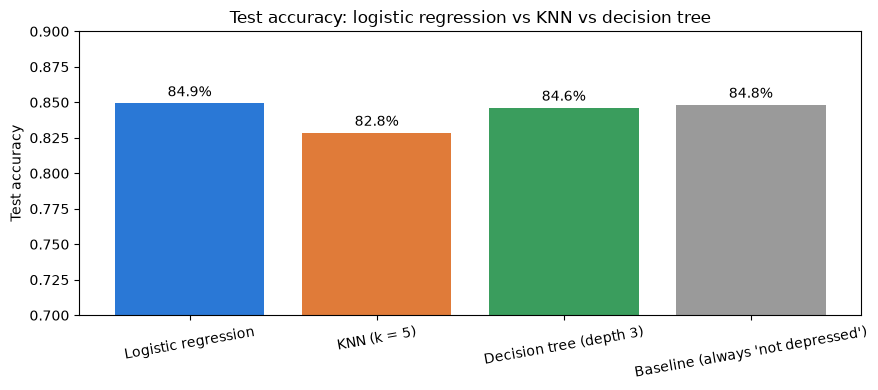

In [3]:
acc = comparison.loc["Accuracy"]

plt.figure(figsize=(9, 4))
bars = plt.bar(acc.index, acc.values, color=["#2a78d6", "#e07b39", "#3a9d5d", "#9a9a9a"])
for bar, value in zip(bars, acc.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.005, f"{value:.1%}", ha="center")
plt.ylim(0.7, 0.9)
plt.ylabel("Test accuracy")
plt.title("Test accuracy: logistic regression vs KNN vs decision tree")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig("comparison_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()

## **Explanation: the accuracy chart**

- Each bar is one model's test accuracy; the grey bar on the right is the baseline of always predicting "not depressed".
- **Note the y-axis starts at 70%, not 0%.** This zooms in so the small differences are visible, but it also makes them look bigger than they are. Logistic regression (84.9%), the decision tree (84.6%) and the baseline (84.8%) are within 3 adolescents of each other.
- **KNN's bar is visibly lower** (82.8%): it is the only model clearly below the baseline.
- The chart only shows accuracy, so it hides the main difference between the models, which is **how many real cases each catches** (Step 1). The chart should be presented together with recall, or it suggests the models are nearly identical, and nearly as good as a model that catches nobody.

---
## Step 3. The regression models (linear regression, Ridge, Lasso)

These models predict the BDI-II **score**, not the yes/no label, so they are compared in two ways:
1. **On their own task**, with R² and MAE for `bdi_total`.
2. **On the threshold question**, by labelling anyone with a predicted score of 14 or above as "depressed" (the same rule that defines `depressed`), as in `modelling.ipynb`. This puts them on the same footing as the three classifiers.

In [4]:
reg_models = ["Linear regression", "+Ridge (alpha=50)", "+Lasso (alpha=1)"]
y_score = regression["actual_bdi_total"]

regression_scores = pd.DataFrame({
    name: {
        "Test R²": r2_score(y_score, regression[name]),
        "Test MAE": mean_absolute_error(y_score, regression[name]),
        "Highest predicted score": regression[name].max(),
    }
    for name in reg_models
})
regression_scores.round(3)

,Linear regression,+Ridge (alpha=50),+Lasso (alpha=1)
Test R²,0.220,0.220,0.170
Test MAE,4.886,4.887,5.122
Highest predicted score,21.982,21.868,16.124


In [5]:
# Apply the clinical cut-off of 14 to each regression model's predicted scores
for name in reg_models:
    predicted_above = (regression[name] >= 14).astype(int)
    comparison[f"{name}, cut-off 14"] = pd.Series(classification_metrics(y_test, predicted_above))

comparison.round(3)

,Logistic regression,KNN (k = 5),Decision tree (depth 3),Baseline (always 'not depressed'),"Linear regression, cut-off 14","+Ridge (alpha=50), cut-off 14","+Lasso (alpha=1), cut-off 14"
Accuracy,0.849,0.828,0.846,0.848,0.854,0.853,0.851
Precision (depressed),0.511,0.362,0.438,NaN,0.565,0.556,0.615
Recall (depressed),0.158,0.171,0.048,NaN,0.178,0.171,0.055
F1 (depressed),0.241,0.233,0.086,NaN,0.271,0.262,0.101
Flagged as depressed,45.000,69.000,16.000,NaN,46.000,45.000,13.000
Real cases caught,23.000,25.000,7.000,NaN,26.000,25.000,8.000


## **Explanation: the regression models**

**R² and MAE table (predicting the score itself)**
- **Linear regression and Ridge are almost identical** (test R² 0.220, MAE about 4.9 BDI points). The linear model was not overfitting, so Ridge's penalty has almost nothing to correct.
- **Lasso (alpha = 1) is worse** (test R² 0.170). It removed four features, including both screen-time measures, and lost some real information.
- **Highest predicted score:** about 22 for linear regression and Ridge, and only about 16 for Lasso, although real scores in the test set go up to 49. This is the **compression** seen in `modelling.ipynb`'s residual plot: the models pull predictions towards the average. Lasso's stronger penalty compresses them even more.

**Combined table (all six models on the threshold question)**
- **Linear regression with a cut-off of 14 has the best accuracy (0.854), recall (0.178) and F1 (0.271) of all six models.** It catches 26 of 146 real cases while flagging 46, so it slightly beats logistic regression on every metric.
- **Ridge is nearly identical** (25 caught, accuracy 0.853).
- **Lasso drops sharply** (8 caught, recall 0.055). Because its predictions rarely reach 14, it almost never flags anyone, much like the depth-3 tree. It has the highest precision (0.615), but only because it flags just the 13 most obvious adolescents: high precision means little when so few are flagged.
- The differences between the best models are small: linear regression catches **3 more** real cases than logistic regression and 1 more than KNN.

**Why is a regression model competitive on a classification question?** It sees the full score (for example, a 13 and a 2 are very different), while the classifiers only see "above or below 14". The extra information gives it a slight edge, although it is still limited by the same features.

---
## Summary: comparing all models

| | Accuracy | Recall (depressed) | Real cases caught (of 146) | Overfitting? |
|---|---|---|---|---|
| Baseline (always "not depressed") | 0.848 | 0.000 | 0 | n/a |
| Logistic regression | 0.849 | 0.158 | 23 | No |
| KNN (k = 5) | 0.828 | 0.171 | 25 | Small gap |
| Decision tree (depth 3) | 0.846 | 0.048 | 7 | No (the unrestricted tree overfits badly) |
| Linear regression, cut-off 14 | **0.854** | **0.178** | **26** | No |
| Ridge, cut-off 14 | 0.853 | 0.171 | 25 | No |
| Lasso, cut-off 14 | 0.851 | 0.055 | 8 | No |

1. **No model is a reliable screening tool.** The best model catches about 18% of adolescents above the clinical threshold, and accuracy barely improves on labelling everyone "not depressed". This is consistent across all six models, which points to a limit of the **features** (self-reported screen time, sleep and sex), not the choice of model.
2. **The simpler, linear models do as well as or better than the more flexible ones.** Linear and logistic regression beat KNN and the decision tree, and making the tree more flexible only produced overfitting. There is not enough non-linear structure in these features for the flexible models to exploit.
3. **All models agree on which factors matter.** The decision tree's first two questions (sleep quality, then sex), the standardised regression coefficients (sleep quality +2.24, sex +1.60) and Lasso's drop-out order (sleep quality removed last) all point the same way: **poorer sleep quality and being a girl are the strongest predictors of higher BDI-II scores**, with screen time playing a smaller role.
4. **Regularisation was not needed for the linear model** (Ridge changes nothing, Lasso at alpha = 1 removes useful information). It **was** essential for the decision tree, where it was the difference between a test accuracy of 0.771 and 0.846.
5. **Accuracy alone would be misleading here.** On accuracy, the depth-1 tree, which catches nobody, looks as good as anything. Recall, precision and the baseline have to be reported together.

> As in the individual notebooks, these results come from a single train/test split. Week 10's cross-validation would show how stable the small differences between models are.